In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

# Load the dataset
# Download from Kaggle: "hotel booking demand" by Jesse Mostipak
# File name: hotel_bookings.csv

df = pd.read_csv('hotel_bookings.csv')
print(df.shape)
print(df.columns.tolist())
print(df['hotel'].value_counts())

(119390, 32)
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']
hotel
City Hotel      79330
Resort Hotel    40060
Name: count, dtype: int64


In [3]:
# Filter to City Hotel, non-cancelled bookings only
city = df[(df['hotel'] == 'City Hotel') & (df['is_canceled'] == 0)].copy()

# Build arrival date
month_map = {'January':1,'February':2,'March':3,'April':4,'May':5,'June':6,
             'July':7,'August':8,'September':9,'October':10,'November':11,'December':12}
city['month_num'] = city['arrival_date_month'].map(month_map)
city['arrival_date'] = pd.to_datetime(dict(
    year=city['arrival_date_year'],
    month=city['month_num'],
    day=city['arrival_date_day_of_month']
))

# Daily summary: count of arrivals and average daily rate
daily = city.groupby('arrival_date').agg(
    rooms_sold=('adr', 'count'),
    avg_adr=('adr', 'mean')
).reset_index()

# Assume hotel capacity of 200 rooms (reasonable for a city hotel)
CAPACITY = 200
daily['occupancy_rate'] = (daily['rooms_sold'] / CAPACITY).clip(upper=1.0)

print(daily.shape)
print(daily.describe())
print(daily.head())

(788, 4)
                        arrival_date  rooms_sold     avg_adr  occupancy_rate
count                            788  788.000000  788.000000      788.000000
mean   2016-08-02 10:17:39.898477056   58.664975  101.164790        0.293299
min              2015-07-01 00:00:00    1.000000    0.000000        0.005000
25%              2016-01-18 18:00:00   39.000000   83.941200        0.195000
50%              2016-08-02 12:00:00   59.000000  100.320353        0.295000
75%              2017-02-15 06:00:00   74.250000  119.094719        0.371250
max              2017-08-31 00:00:00  204.000000  169.147200        1.000000
std                              NaN   27.278077   23.804615        0.136257
  arrival_date  rooms_sold    avg_adr  occupancy_rate
0   2015-07-01          65  95.076923           0.325
1   2015-07-02           1  58.670000           0.005
2   2015-07-03          10  74.527000           0.050
3   2015-07-04           9  63.777778           0.045
4   2015-07-06           1  

In [4]:
# Baseline parameters from data
BASE_ADR = daily['avg_adr'].median()
BASE_OCC = daily['occupancy_rate'].median()

print(f"Baseline ADR: {BASE_ADR:.2f}")
print(f"Baseline Occupancy: {BASE_OCC:.2f}")

import gymnasium as gym
from gymnasium import spaces

class HotelPricingEnv(gym.Env):
    """
    Simple single-night hotel pricing environment.
    State: (occupancy_rate, days_to_arrival) — both discretized
    Action: price multiplier index (0=low, 1=mid, 2=high)
    Reward: depends on reward_mode
    """

    PRICE_MULTIPLIERS = [0.7, 1.0, 1.3]  # 70%, 100%, 130% of base rate
    RATE_FLOOR = 0.80  # rate floor for RevPAR mode

    def __init__(self, reward_mode='revenue', base_adr=BASE_ADR, capacity=200):
        super().__init__()
        self.reward_mode = reward_mode
        self.base_adr = base_adr
        self.capacity = capacity

        # State: occupancy bucket (0-4) x days_to_arrival bucket (0-4)
        self.observation_space = spaces.Discrete(25)
        # Action: 3 price multipliers
        self.action_space = spaces.Discrete(3)

        self.state = None

    def _encode_state(self, occ, dta):
        occ_bucket = min(int(occ * 5), 4)   # 0-4
        dta_bucket = min(dta // 20, 4)       # 0-4 for dta 0-100
        return occ_bucket * 5 + dta_bucket

    def reset(self, seed=None):
        # Random starting occupancy and days to arrival
        occ = np.random.choice(daily['occupancy_rate'].values)
        dta = np.random.randint(1, 90)
        self.occ = occ
        self.dta = dta
        return self._encode_state(occ, dta), {}

    def step(self, action):
        multiplier = self.PRICE_MULTIPLIERS[action]
        price = self.base_adr * multiplier

        # Demand response: higher price reduces rooms sold
        # Elasticity-based: 10% price increase reduces demand by ~5%
        price_effect = (multiplier - 1.0) * 0.5
        rooms_sold = int(self.capacity * self.occ * (1 - price_effect))
        rooms_sold = max(0, min(rooms_sold, self.capacity))
        rooms_empty = self.capacity - rooms_sold

        # Revenue
        revenue = price * rooms_sold
        revpar = revenue / self.capacity

        # Three reward modes
        if self.reward_mode == 'revenue':
            reward = revenue / 10000  # scaled

        elif self.reward_mode == 'revpar_floor':
            if multiplier < self.RATE_FLOOR:
                reward = 0.0  # penalize pricing below floor
            else:
                reward = revpar / 100  # scaled

        elif self.reward_mode == 'occupancy_weighted':
            # Reward both filling rooms and maintaining margin
            occ_reward = rooms_sold / self.capacity
            margin_reward = (price - self.base_adr * 0.6) / self.base_adr
            reward = 0.5 * occ_reward + 0.5 * margin_reward

        # Transition: occupancy drifts randomly next period
        self.occ = min(1.0, self.occ + np.random.uniform(-0.05, 0.1))
        self.dta = max(0, self.dta - 1)
        done = self.dta == 0

        return self._encode_state(self.occ, self.dta), reward, done, False, {}


# Quick sanity check
for mode in ['revenue', 'revpar_floor', 'occupancy_weighted']:
    env = HotelPricingEnv(reward_mode=mode)
    obs, _ = env.reset()
    obs2, reward, done, _, _ = env.step(1)
    print(f"{mode}: obs={obs}, reward={reward:.4f}")

Baseline ADR: 100.32
Baseline Occupancy: 0.29
revenue: obs=6, reward=0.6822
revpar_floor: obs=8, reward=0.3260
occupancy_weighted: obs=15, reward=0.5150


In [5]:
!pip install gymnasium --quiet

In [6]:
def train_qlearning(reward_mode, episodes=500, alpha=0.1, gamma=0.95, epsilon=0.1):
    env = HotelPricingEnv(reward_mode=reward_mode)
    Q = np.zeros((25, 3))  # 25 states x 3 actions
    rewards_per_episode = []

    for ep in range(episodes):
        obs, _ = env.reset()
        total_reward = 0
        done = False

        while not done:
            # Epsilon-greedy action selection
            if np.random.random() < epsilon:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q[obs])

            next_obs, reward, done, _, _ = env.step(action)

            # Q-learning update
            Q[obs, action] += alpha * (
                reward + gamma * np.max(Q[next_obs]) - Q[obs, action]
            )

            obs = next_obs
            total_reward += reward

        rewards_per_episode.append(total_reward)

    return Q, rewards_per_episode


# Train all three
print("Training revenue mode...")
Q_rev, rewards_rev = train_qlearning('revenue')

print("Training revpar_floor mode...")
Q_floor, rewards_floor = train_qlearning('revpar_floor')

print("Training occupancy_weighted mode...")
Q_occ, rewards_occ = train_qlearning('occupancy_weighted')

print("Done. All three trained.")

Training revenue mode...
Training revpar_floor mode...
Training occupancy_weighted mode...
Done. All three trained.


Revenue policy:             ['Low (70%)', 'Low (70%)', 'Low (70%)', 'Low (70%)', 'High (130%)']
RevPAR floor policy:        ['Base (100%)', 'Low (70%)', 'Base (100%)', 'Low (70%)', 'High (130%)']
Occupancy weighted policy:  ['Low (70%)', 'Low (70%)', 'Low (70%)', 'Low (70%)', 'High (130%)']


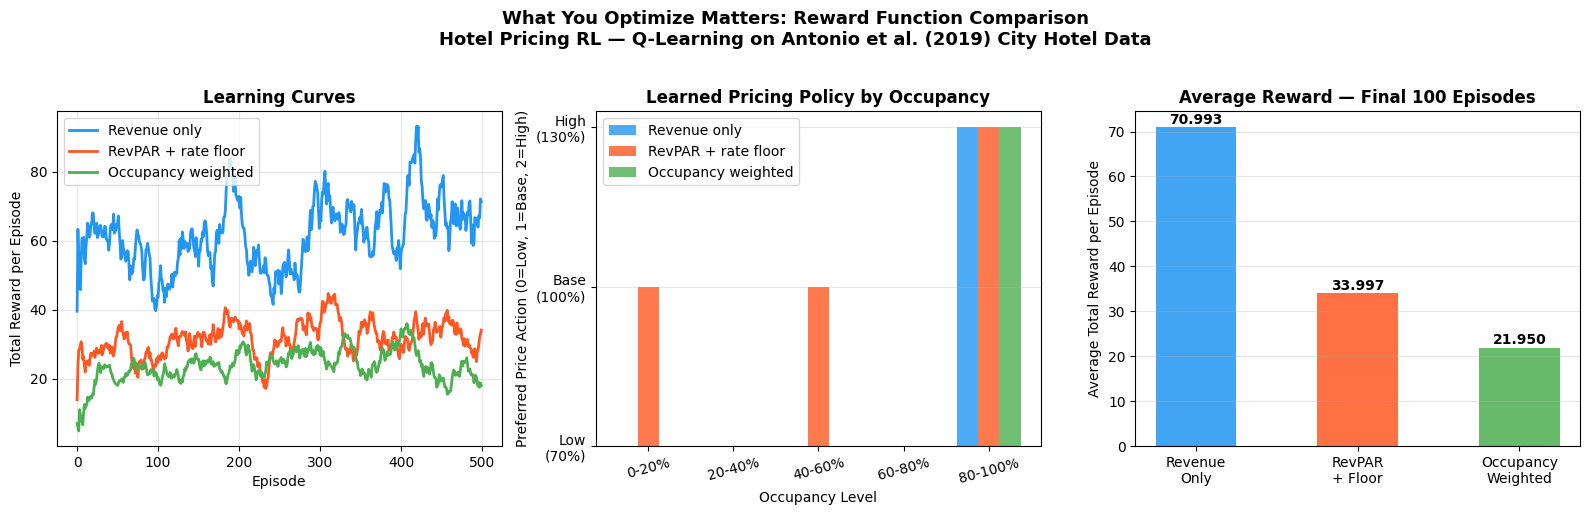


Final 100-episode average rewards:
  Revenue only: 70.9932
  RevPAR + floor: 33.9969
  Occupancy weighted: 21.9497


In [7]:
# Extract learned policy for each mode
# Policy = which price action the agent prefers at each occupancy level
# We average across DTA buckets to get a clean occupancy vs price picture

price_labels = ['Low (70%)', 'Base (100%)', 'High (130%)']
occ_labels = ['0-20%', '20-40%', '40-60%', '60-80%', '80-100%']

def extract_policy_by_occupancy(Q):
    """For each occupancy bucket, find the most common preferred action across DTA states."""
    policy = []
    for occ_bucket in range(5):
        actions = []
        for dta_bucket in range(5):
            state = occ_bucket * 5 + dta_bucket
            actions.append(np.argmax(Q[state]))
        policy.append(np.bincount(actions).argmax())
    return policy

policy_rev = extract_policy_by_occupancy(Q_rev)
policy_floor = extract_policy_by_occupancy(Q_floor)
policy_occ = extract_policy_by_occupancy(Q_occ)

print("Revenue policy:            ", [price_labels[a] for a in policy_rev])
print("RevPAR floor policy:       ", [price_labels[a] for a in policy_floor])
print("Occupancy weighted policy: ", [price_labels[a] for a in policy_occ])

# Smooth reward curves
def smooth(x, window=20):
    return pd.Series(x).rolling(window, min_periods=1).mean().values

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("What You Optimize Matters: Reward Function Comparison\nHotel Pricing RL — Q-Learning on Antonio et al. (2019) City Hotel Data",
             fontsize=13, fontweight='bold', y=1.02)

# Plot 1: Learning curves
ax1 = axes[0]
ax1.plot(smooth(rewards_rev),   color='#2196F3', label='Revenue only',          linewidth=2)
ax1.plot(smooth(rewards_floor), color='#FF5722', label='RevPAR + rate floor',   linewidth=2)
ax1.plot(smooth(rewards_occ),   color='#4CAF50', label='Occupancy weighted',    linewidth=2)
ax1.set_title('Learning Curves', fontsize=12, fontweight='bold')
ax1.set_xlabel('Episode')
ax1.set_ylabel('Total Reward per Episode')
ax1.legend()
ax1.grid(alpha=0.3)

# Plot 2: Learned pricing policy by occupancy
ax2 = axes[1]
x = np.arange(5)
width = 0.25
ax2.bar(x - width, policy_rev,   width, label='Revenue only',        color='#2196F3', alpha=0.8)
ax2.bar(x,         policy_floor, width, label='RevPAR + rate floor', color='#FF5722', alpha=0.8)
ax2.bar(x + width, policy_occ,   width, label='Occupancy weighted',  color='#4CAF50', alpha=0.8)
ax2.set_title('Learned Pricing Policy by Occupancy', fontsize=12, fontweight='bold')
ax2.set_xlabel('Occupancy Level')
ax2.set_ylabel('Preferred Price Action (0=Low, 1=Base, 2=High)')
ax2.set_xticks(x)
ax2.set_xticklabels(occ_labels, rotation=15)
ax2.set_yticks([0, 1, 2])
ax2.set_yticklabels(['Low\n(70%)', 'Base\n(100%)', 'High\n(130%)'])
ax2.legend()
ax2.grid(alpha=0.3, axis='y')

# Plot 3: Average reward comparison (final 100 episodes)
ax3 = axes[2]
final_means = [np.mean(rewards_rev[-100:]),
               np.mean(rewards_floor[-100:]),
               np.mean(rewards_occ[-100:])]
colors = ['#2196F3', '#FF5722', '#4CAF50']
bars = ax3.bar(['Revenue\nOnly', 'RevPAR\n+ Floor', 'Occupancy\nWeighted'],
               final_means, color=colors, alpha=0.85, width=0.5)
ax3.set_title('Average Reward — Final 100 Episodes', fontsize=12, fontweight='bold')
ax3.set_ylabel('Average Total Reward per Episode')
for bar, val in zip(bars, final_means):
    ax3.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
             f'{val:.3f}', ha='center', va='bottom', fontweight='bold')
ax3.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('reward_function_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFinal 100-episode average rewards:")
for name, val in zip(['Revenue only', 'RevPAR + floor', 'Occupancy weighted'], final_means):
    print(f"  {name}: {val:.4f}")

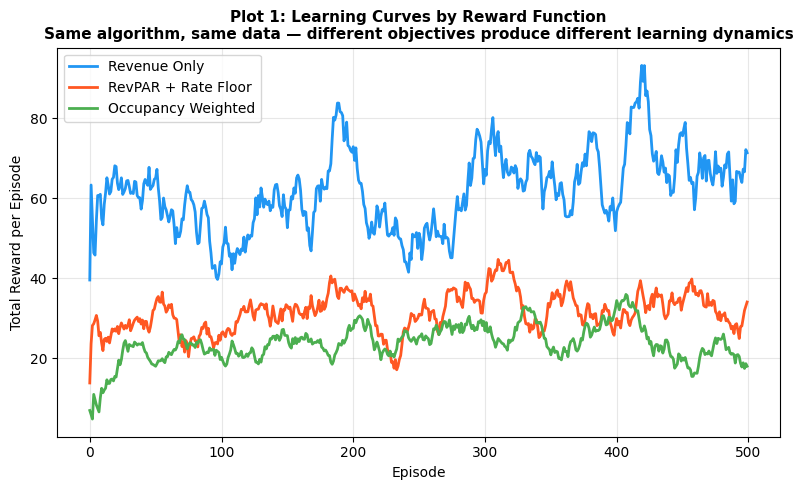

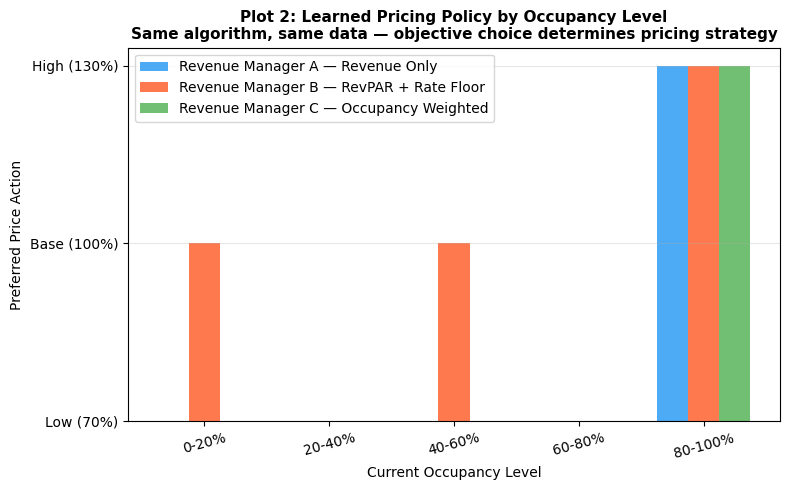

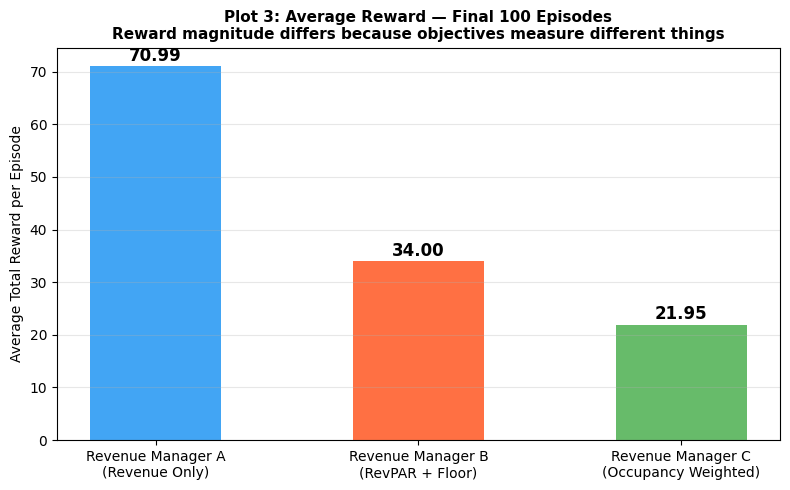

In [8]:
fig1, ax = plt.subplots(figsize=(8, 5))
ax.plot(smooth(rewards_rev),   color='#2196F3', label='Revenue Only',        linewidth=2)
ax.plot(smooth(rewards_floor), color='#FF5722', label='RevPAR + Rate Floor', linewidth=2)
ax.plot(smooth(rewards_occ),   color='#4CAF50', label='Occupancy Weighted',  linewidth=2)
ax.set_title('Plot 1: Learning Curves by Reward Function\nSame algorithm, same data — different objectives produce different learning dynamics',
             fontsize=11, fontweight='bold')
ax.set_xlabel('Episode')
ax.set_ylabel('Total Reward per Episode')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('plot1_learning_curves.png', dpi=150, bbox_inches='tight')
plt.show()

fig2, ax = plt.subplots(figsize=(8, 5))
x = np.arange(5)
width = 0.25
ax.bar(x - width, policy_rev,   width, label='Revenue Manager A — Revenue Only',        color='#2196F3', alpha=0.8)
ax.bar(x,         policy_floor, width, label='Revenue Manager B — RevPAR + Rate Floor', color='#FF5722', alpha=0.8)
ax.bar(x + width, policy_occ,   width, label='Revenue Manager C — Occupancy Weighted',  color='#4CAF50', alpha=0.8)
ax.set_title('Plot 2: Learned Pricing Policy by Occupancy Level\nSame algorithm, same data — objective choice determines pricing strategy',
             fontsize=11, fontweight='bold')
ax.set_xlabel('Current Occupancy Level')
ax.set_ylabel('Preferred Price Action')
ax.set_xticks(x)
ax.set_xticklabels(occ_labels, rotation=15)
ax.set_yticks([0, 1, 2])
ax.set_yticklabels(['Low (70%)', 'Base (100%)', 'High (130%)'])
ax.legend(loc='upper left')
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('plot2_pricing_policy.png', dpi=150, bbox_inches='tight')
plt.show()

fig3, ax = plt.subplots(figsize=(8, 5))
colors = ['#2196F3', '#FF5722', '#4CAF50']
bars = ax.bar(['Revenue Manager A\n(Revenue Only)',
               'Revenue Manager B\n(RevPAR + Floor)',
               'Revenue Manager C\n(Occupancy Weighted)'],
              final_means, color=colors, alpha=0.85, width=0.5)
ax.set_title('Plot 3: Average Reward — Final 100 Episodes\nReward magnitude differs because objectives measure different things',
             fontsize=11, fontweight='bold')
ax.set_ylabel('Average Total Reward per Episode')
for bar, val in zip(bars, final_means):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{val:.2f}', ha='center', va='bottom', fontweight='bold', fontsize=12)
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('plot3_reward_comparison.png', dpi=150, bbox_inches='tight')
plt.show()

Policy Evaluation on Common Metrics (200 episodes):
  Revenue Manager A — Revenue: 731508.8  |  Occupancy: 0.684
  Revenue Manager B — Revenue: 741276.7  |  Occupancy: 0.621
  Revenue Manager C — Revenue: 697233.8  |  Occupancy: 0.642


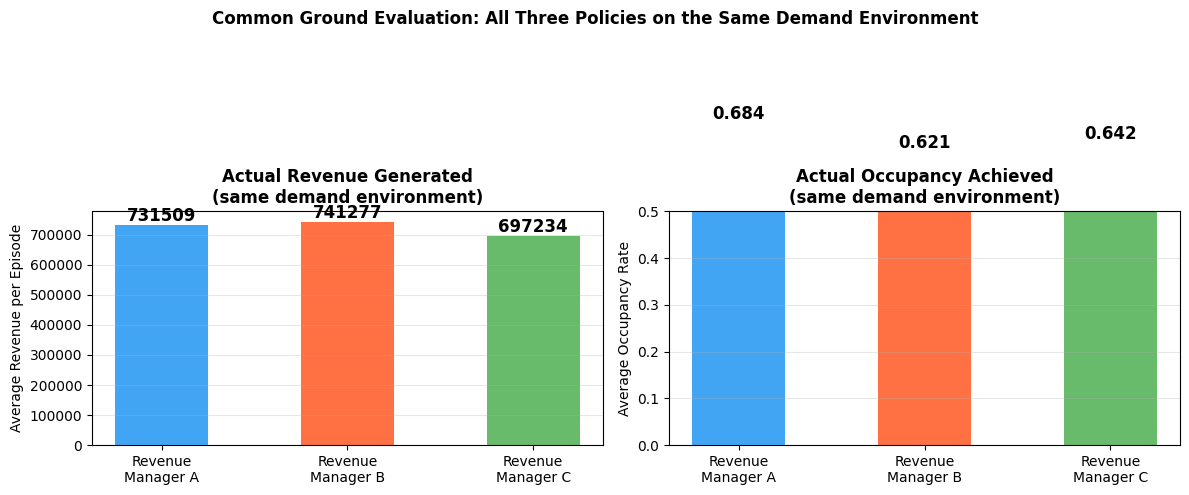

In [9]:
# Evaluate all three trained policies on a common metric
# Run 200 evaluation episodes, record actual rooms sold and actual revenue
# Use the same demand function for all three so numbers are comparable

def evaluate_policy(Q, episodes=200):
    env = HotelPricingEnv(reward_mode='revenue')  # same env for all
    total_revenues = []
    total_occupancies = []

    for ep in range(episodes):
        obs, _ = env.reset()
        ep_revenue = 0
        ep_rooms_sold = 0
        ep_capacity = 0
        done = False

        while not done:
            action = np.argmax(Q[obs])  # greedy, no exploration
            multiplier = HotelPricingEnv.PRICE_MULTIPLIERS[action]
            price = BASE_ADR * multiplier

            obs, _, done, _, _ = env.step(action)

            # Recompute actual rooms sold from the action taken
            price_effect = (multiplier - 1.0) * 0.5
            rooms_sold = int(CAPACITY * env.occ * (1 - price_effect))
            rooms_sold = max(0, min(rooms_sold, CAPACITY))

            ep_revenue += price * rooms_sold
            ep_rooms_sold += rooms_sold
            ep_capacity += CAPACITY

        total_revenues.append(ep_revenue)
        total_occupancies.append(ep_rooms_sold / ep_capacity)

    return np.mean(total_revenues), np.mean(total_occupancies)


rev_revenue, rev_occ = evaluate_policy(Q_rev)
floor_revenue, floor_occ = evaluate_policy(Q_floor)
occ_revenue, occ_occ = evaluate_policy(Q_occ)

print("Policy Evaluation on Common Metrics (200 episodes):")
print(f"  Revenue Manager A — Revenue: {rev_revenue:.1f}  |  Occupancy: {rev_occ:.3f}")
print(f"  Revenue Manager B — Revenue: {floor_revenue:.1f}  |  Occupancy: {floor_occ:.3f}")
print(f"  Revenue Manager C — Revenue: {occ_revenue:.1f}  |  Occupancy: {occ_occ:.3f}")

# Plot side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
fig.suptitle("Common Ground Evaluation: All Three Policies on the Same Demand Environment",
             fontsize=12, fontweight='bold')

managers = ['Revenue\nManager A', 'Revenue\nManager B', 'Revenue\nManager C']
colors = ['#2196F3', '#FF5722', '#4CAF50']

# Revenue comparison
ax1 = axes[0]
bars = ax1.bar(managers, [rev_revenue, floor_revenue, occ_revenue],
               color=colors, alpha=0.85, width=0.5)
ax1.set_title('Actual Revenue Generated\n(same demand environment)', fontweight='bold')
ax1.set_ylabel('Average Revenue per Episode')
for bar, val in zip(bars, [rev_revenue, floor_revenue, occ_revenue]):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50,
             f'{val:.0f}', ha='center', va='bottom', fontweight='bold', fontsize=12)
ax1.grid(alpha=0.3, axis='y')

# Occupancy comparison
ax2 = axes[1]
bars = ax2.bar(managers, [rev_occ, floor_occ, occ_occ],
               color=colors, alpha=0.85, width=0.5)
ax2.set_title('Actual Occupancy Achieved\n(same demand environment)', fontweight='bold')
ax2.set_ylabel('Average Occupancy Rate')
ax2.set_ylim(0, 0.5)
for bar, val in zip(bars, [rev_occ, floor_occ, occ_occ]):
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
             f'{val:.3f}', ha='center', va='bottom', fontweight='bold', fontsize=12)
ax2.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('plot4_common_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

Price Selection Distribution (% of time each price was chosen):
                                  Low (70%)  Base (100%)  High (130%)
Revenue Manager A                     43.1%         8.3%        48.5%
Revenue Manager B                     11.9%        15.0%        73.2%
Revenue Manager C                     35.8%         0.0%        64.2%


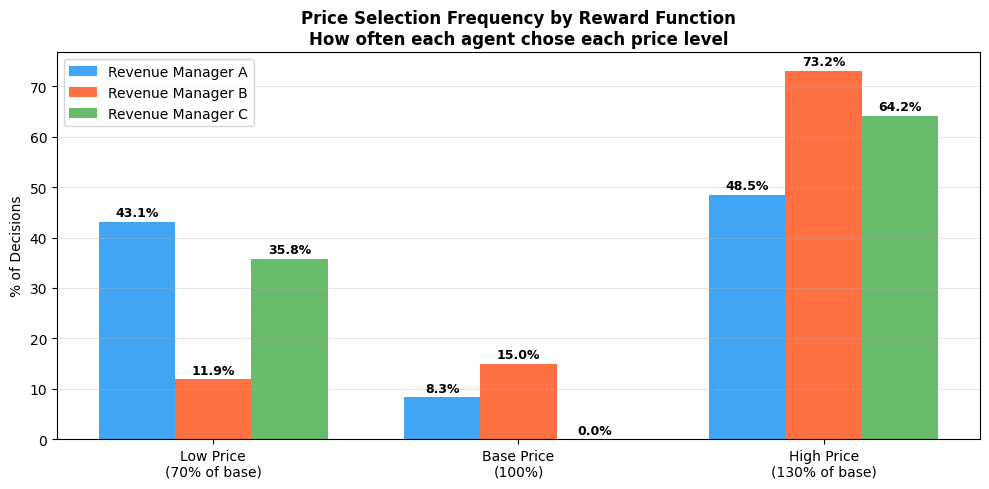

In [10]:
def get_price_distribution(Q, episodes=200):
    env = HotelPricingEnv(reward_mode='revenue')
    price_counts = [0, 0, 0]  # low, base, high

    for ep in range(episodes):
        obs, _ = env.reset()
        done = False
        while not done:
            action = np.argmax(Q[obs])
            price_counts[action] += 1
            obs, _, done, _, _ = env.step(action)

    total = sum(price_counts)
    return [c / total * 100 for c in price_counts]

dist_rev   = get_price_distribution(Q_rev)
dist_floor = get_price_distribution(Q_floor)
dist_occ   = get_price_distribution(Q_occ)

print("Price Selection Distribution (% of time each price was chosen):")
print(f"{'':30} {'Low (70%)':>12} {'Base (100%)':>12} {'High (130%)':>12}")
print(f"{'Revenue Manager A':30} {dist_rev[0]:>11.1f}% {dist_rev[1]:>11.1f}% {dist_rev[2]:>11.1f}%")
print(f"{'Revenue Manager B':30} {dist_floor[0]:>11.1f}% {dist_floor[1]:>11.1f}% {dist_floor[2]:>11.1f}%")
print(f"{'Revenue Manager C':30} {dist_occ[0]:>11.1f}% {dist_occ[1]:>11.1f}% {dist_occ[2]:>11.1f}%")

# Plot
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(3)
width = 0.25
ax.bar(x - width, dist_rev,   width, label='Revenue Manager A', color='#2196F3', alpha=0.85)
ax.bar(x,         dist_floor, width, label='Revenue Manager B', color='#FF5722', alpha=0.85)
ax.bar(x + width, dist_occ,   width, label='Revenue Manager C', color='#4CAF50', alpha=0.85)
for bars, dists in zip(
    [ax.containers[0], ax.containers[1], ax.containers[2]],
    [dist_rev, dist_floor, dist_occ]
):
    for bar, val in zip(bars, dists):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.5,
                f'{val:.1f}%',
                ha='center', va='bottom',
                fontweight='bold', fontsize=9)
ax.set_title('Price Selection Frequency by Reward Function\nHow often each agent chose each price level',
             fontsize=12, fontweight='bold')
ax.set_ylabel('% of Decisions')
ax.set_xticks(x)
ax.set_xticklabels(['Low Price\n(70% of base)', 'Base Price\n(100%)', 'High Price\n(130% of base)'])
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('plot5_price_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

In [11]:
# Train/test split on the daily data
daily_sorted = daily.sort_values('arrival_date').reset_index(drop=True)
split_idx = int(len(daily_sorted) * 0.8)

train_data = daily_sorted.iloc[:split_idx]
test_data  = daily_sorted.iloc[split_idx:]

print(f"Train period: {train_data['arrival_date'].min().date()} to {train_data['arrival_date'].max().date()} — {len(train_data)} days")
print(f"Test period:  {test_data['arrival_date'].min().date()} to {test_data['arrival_date'].max().date()} — {len(test_data)} days")

# Recalibrate baseline from training data only
TRAIN_BASE_ADR = train_data['avg_adr'].median()
print(f"Train baseline ADR: {TRAIN_BASE_ADR:.2f}")

# Retrain all three policies on train data environment
class HotelPricingEnvTrain(HotelPricingEnv):
    def __init__(self, reward_mode='revenue'):
        super().__init__(reward_mode=reward_mode, base_adr=TRAIN_BASE_ADR)

print("\nRetraining on train period...")
Q_rev_t,   rewards_rev_t   = train_qlearning('revenue',             episodes=500)
Q_floor_t, rewards_floor_t = train_qlearning('revpar_floor',        episodes=500)
Q_occ_t,   rewards_occ_t   = train_qlearning('occupancy_weighted',  episodes=500)
print("Done.")

Train period: 2015-07-01 to 2017-03-26 — 630 days
Test period:  2017-03-27 to 2017-08-31 — 158 days
Train baseline ADR: 92.29

Retraining on train period...
Done.


Bucket-Level Validation: Agent Price vs Actual ADR

   Occupancy   N Days   Actual ADR  Rev A Price  Rev B Price  Rev C Price    MAE A    MAE B    MAE C
----------------------------------------------------------------------------------------------------
       0-20%        4       123.30        64.60        64.60        64.60    58.69    58.69    58.69
      20-40%      115       130.58        64.60       119.98        64.60    65.98    10.60    65.98
      40-60%       38       125.45        64.60       119.98        64.60    60.85     5.47    60.85
      60-80%        1       129.19        64.60        64.60        64.60    64.59    64.59    64.59
     80-100%        0          nan       119.98       119.98       119.98      nan      nan      nan

Overall Bucket MAE — Revenue A: 62.53  |  RevPAR B: 34.84  |  Occupancy C: 62.53
Closest to actual market pricing: Revenue Manager B


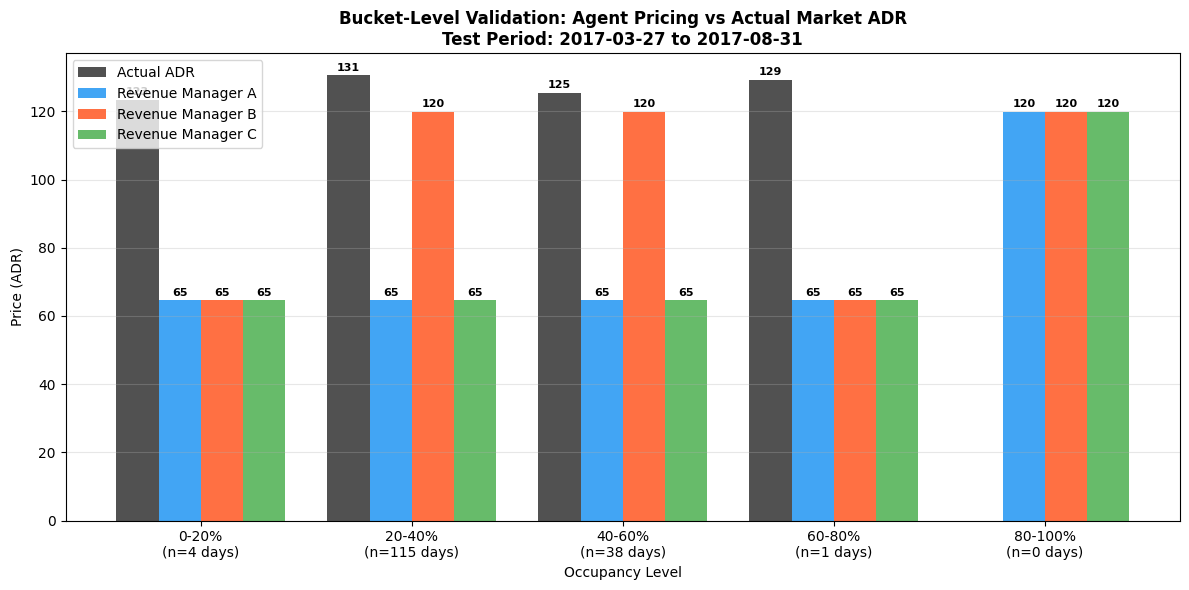

In [12]:
# Bucket-level validation: compare agent price vs actual ADR by occupancy bucket

def bucket_level_validation(Q, test_df, base_adr=TRAIN_BASE_ADR):
    """
    For each occupancy bucket, compute:
    - Agent's chosen price (from learned policy)
    - Actual average ADR from test data at that occupancy level
    """
    results = []

    for occ_bucket in range(5):
        # Agent's preferred price for this occupancy bucket
        # Average across DTA buckets
        actions = [np.argmax(Q[occ_bucket * 5 + dta]) for dta in range(5)]
        preferred_action = np.bincount(actions).argmax()
        agent_price = base_adr * HotelPricingEnv.PRICE_MULTIPLIERS[preferred_action]

        # Actual ADR from test data in this occupancy bucket
        occ_low  = occ_bucket * 0.2
        occ_high = (occ_bucket + 1) * 0.2
        bucket_days = test_df[
            (test_df['occupancy_rate'] >= occ_low) &
            (test_df['occupancy_rate'] <  occ_high)
        ]

        if len(bucket_days) > 0:
            actual_adr = bucket_days['avg_adr'].mean()
            n_days = len(bucket_days)
        else:
            actual_adr = np.nan
            n_days = 0

        results.append({
            'occ_bucket': occ_labels[occ_bucket],
            'agent_price': agent_price,
            'actual_adr': actual_adr,
            'abs_error': abs(agent_price - actual_adr) if n_days > 0 else np.nan,
            'n_days': n_days,
            'preferred_action': price_labels[preferred_action]
        })

    return pd.DataFrame(results)


df_rev   = bucket_level_validation(Q_rev_t,   test_data)
df_floor = bucket_level_validation(Q_floor_t, test_data)
df_occ   = bucket_level_validation(Q_occ_t,   test_data)

# Print comparison table
print("Bucket-Level Validation: Agent Price vs Actual ADR")
print(f"\n{'Occupancy':>12} {'N Days':>8} {'Actual ADR':>12} {'Rev A Price':>12} {'Rev B Price':>12} {'Rev C Price':>12} {'MAE A':>8} {'MAE B':>8} {'MAE C':>8}")
print("-" * 100)

for i in range(5):
    row_r = df_rev.iloc[i]
    row_f = df_floor.iloc[i]
    row_o = df_occ.iloc[i]
    print(f"{row_r['occ_bucket']:>12} {row_r['n_days']:>8} {row_r['actual_adr']:>12.2f} "
          f"{row_r['agent_price']:>12.2f} {row_f['agent_price']:>12.2f} {row_o['agent_price']:>12.2f} "
          f"{row_r['abs_error']:>8.2f} {row_f['abs_error']:>8.2f} {row_o['abs_error']:>8.2f}")

# Overall MAE per agent
mae_rev_b   = df_rev['abs_error'].mean()
mae_floor_b = df_floor['abs_error'].mean()
mae_occ_b   = df_occ['abs_error'].mean()

print(f"\nOverall Bucket MAE — Revenue A: {mae_rev_b:.2f}  |  RevPAR B: {mae_floor_b:.2f}  |  Occupancy C: {mae_occ_b:.2f}")
winner = ['Revenue Manager A', 'Revenue Manager B', 'Revenue Manager C'][
    np.argmin([mae_rev_b, mae_floor_b, mae_occ_b])
]
print(f"Closest to actual market pricing: {winner}")

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(5)
width = 0.2

ax.bar(x - 1.5*width, df_rev['actual_adr'],   width, label='Actual ADR',           color='#333333', alpha=0.85)
ax.bar(x - 0.5*width, df_rev['agent_price'],   width, label='Revenue Manager A',    color='#2196F3', alpha=0.85)
ax.bar(x + 0.5*width, df_floor['agent_price'], width, label='Revenue Manager B',    color='#FF5722', alpha=0.85)
ax.bar(x + 1.5*width, df_occ['agent_price'],   width, label='Revenue Manager C',    color='#4CAF50', alpha=0.85)

# Add value labels
for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f', padding=2, fontsize=8, fontweight='bold')

ax.set_title('Bucket-Level Validation: Agent Pricing vs Actual Market ADR\nTest Period: 2017-03-27 to 2017-08-31',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Occupancy Level')
ax.set_ylabel('Price (ADR)')
ax.set_xticks(x)
ax.set_xticklabels([f"{occ_labels[i]}\n(n={df_rev.iloc[i]['n_days']} days)" for i in range(5)])
ax.legend()
ax.grid(alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('plot7_bucket_validation.png', dpi=150, bbox_inches='tight')
plt.show()

In [13]:
# Fix 1: Use data-driven price levels instead of fixed multipliers
# Use 25th, 50th, 75th percentile of ADR from full dataset as price actions

P25 = daily['avg_adr'].quantile(0.25)
P50 = daily['avg_adr'].quantile(0.50)
P75 = daily['avg_adr'].quantile(0.75)

print(f"Price levels from data — Low: {P25:.2f}  |  Base: {P50:.2f}  |  High: {P75:.2f}")

class HotelPricingEnvV2(gym.Env):

    PRICE_LEVELS = [P25, P50, P75]
    RATE_FLOOR   = P50 * 0.85

    def __init__(self, reward_mode='revenue', capacity=200):
        super().__init__()
        self.reward_mode = reward_mode
        self.capacity    = capacity
        self.observation_space = spaces.Discrete(25)
        self.action_space      = spaces.Discrete(3)
        self.state = None

    def _encode_state(self, occ, dta):
        occ_bucket = min(int(occ * 5), 4)
        dta_bucket = min(dta // 20, 4)
        return occ_bucket * 5 + dta_bucket

    def reset(self, seed=None):
        occ = np.random.choice(daily['occupancy_rate'].values)
        dta = np.random.randint(1, 90)
        self.occ = occ
        self.dta = dta
        return self._encode_state(occ, dta), {}

    def step(self, action):
        price = self.PRICE_LEVELS[action]

        # Elasticity-based demand — anchored to P50
        price_effect  = ((price - P50) / P50) * 0.5
        rooms_sold    = int(self.capacity * self.occ * (1 - price_effect))
        rooms_sold    = max(0, min(rooms_sold, self.capacity))
        rooms_empty   = self.capacity - rooms_sold
        revenue       = price * rooms_sold
        revpar        = revenue / self.capacity

        if self.reward_mode == 'revenue':
            reward = revenue / 10000

        elif self.reward_mode == 'revpar_floor':
            reward = 0.0 if price < self.RATE_FLOOR else revpar / 100

        elif self.reward_mode == 'occupancy_weighted':
            occ_reward    = rooms_sold / self.capacity
            margin_reward = (price - P25) / P50
            reward        = 0.5 * occ_reward + 0.5 * margin_reward

        self.occ = min(1.0, self.occ + np.random.uniform(-0.05, 0.1))
        self.dta = max(0, self.dta - 1)
        done     = self.dta == 0

        return self._encode_state(self.occ, self.dta), reward, done, False, {}


# Fix 2: More training episodes for proper convergence
def train_qlearning_v2(reward_mode, episodes=3000, alpha=0.1, gamma=0.95, epsilon=0.15):
    env = HotelPricingEnvV2(reward_mode=reward_mode)
    Q   = np.zeros((25, 3))
    rewards_per_episode = []

    for ep in range(episodes):
        obs, _       = env.reset()
        total_reward = 0
        done         = False

        # Decay epsilon over time so agent exploits more as it learns
        eps = max(0.01, epsilon * (1 - ep / episodes))

        while not done:
            if np.random.random() < eps:
                action = env.action_space.sample()
            else:
                action = np.argmax(Q[obs])

            next_obs, reward, done, _, _ = env.step(action)
            Q[obs, action] += alpha * (
                reward + gamma * np.max(Q[next_obs]) - Q[obs, action]
            )
            obs           = next_obs
            total_reward += reward

        rewards_per_episode.append(total_reward)

    return Q, rewards_per_episode


print("\nRetraining with data-driven prices and 3000 episodes...")
Q_rev_v2,   rewards_rev_v2   = train_qlearning_v2('revenue')
Q_floor_v2, rewards_floor_v2 = train_qlearning_v2('revpar_floor')
Q_occ_v2,   rewards_occ_v2   = train_qlearning_v2('occupancy_weighted')
print("Done.")

# Quick policy check
print("\nLearned policies after fix:")
policy_rev_v2   = extract_policy_by_occupancy(Q_rev_v2)
policy_floor_v2 = extract_policy_by_occupancy(Q_floor_v2)
policy_occ_v2   = extract_policy_by_occupancy(Q_occ_v2)

price_labels_v2 = [f'Low ({P25:.0f})', f'Base ({P50:.0f})', f'High ({P75:.0f})']
print("Revenue A:   ", [price_labels_v2[a] for a in policy_rev_v2])
print("RevPAR B:    ", [price_labels_v2[a] for a in policy_floor_v2])
print("Occupancy C: ", [price_labels_v2[a] for a in policy_occ_v2])

Price levels from data — Low: 83.94  |  Base: 100.32  |  High: 119.09

Retraining with data-driven prices and 3000 episodes...
Done.

Learned policies after fix:
Revenue A:    ['Low (84)', 'High (119)', 'Low (84)', 'High (119)', 'High (119)']
RevPAR B:     ['High (119)', 'Base (100)', 'Base (100)', 'High (119)', 'High (119)']
Occupancy C:  ['Low (84)', 'High (119)', 'High (119)', 'High (119)', 'High (119)']


Bucket-Level Validation V2

   Occupancy   N Days   Actual ADR      Rev A      Rev B      Rev C    MAE A    MAE B    MAE C
-----------------------------------------------------------------------------------------------
       0-20%        4       123.30      83.94     119.09      83.94    39.35     4.20    39.35
      20-40%      115       130.58     119.09     100.32     119.09    11.49    30.26    11.49
      40-60%       38       125.45      83.94     100.32     119.09    41.51    25.13     6.36
      60-80%        1       129.19     119.09     119.09     119.09    10.10    10.10    10.10
     80-100%        0          nan     119.09     119.09     119.09      nan      nan      nan

Overall Bucket MAE — Revenue A: 25.61  |  RevPAR B: 17.42  |  Occupancy C: 16.82
Closest to actual market pricing: Revenue Manager C


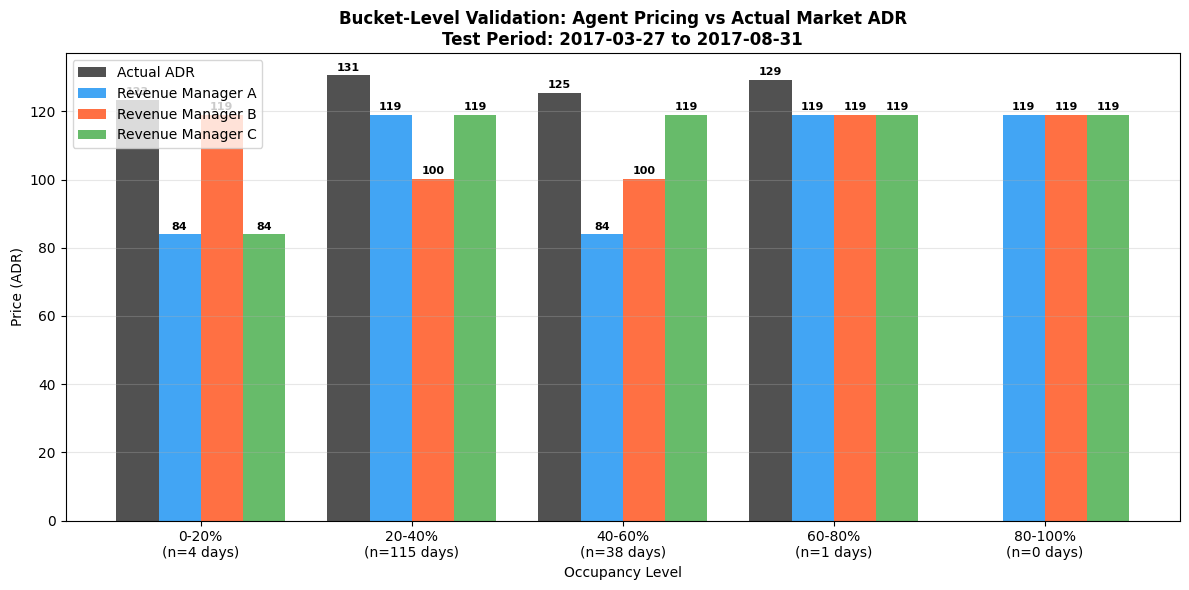

In [14]:
def bucket_level_validation_v2(Q, test_df):
    results = []
    price_levels = HotelPricingEnvV2.PRICE_LEVELS

    for occ_bucket in range(5):
        actions = [np.argmax(Q[occ_bucket * 5 + dta]) for dta in range(5)]
        preferred_action = np.bincount(actions).argmax()
        agent_price = price_levels[preferred_action]

        occ_low  = occ_bucket * 0.2
        occ_high = (occ_bucket + 1) * 0.2
        bucket_days = test_df[
            (test_df['occupancy_rate'] >= occ_low) &
            (test_df['occupancy_rate'] <  occ_high)
        ]

        if len(bucket_days) > 0:
            actual_adr = bucket_days['avg_adr'].mean()
            n_days     = len(bucket_days)
        else:
            actual_adr = np.nan
            n_days     = 0

        results.append({
            'occ_bucket':      occ_labels[occ_bucket],
            'agent_price':     agent_price,
            'actual_adr':      actual_adr,
            'abs_error':       abs(agent_price - actual_adr) if n_days > 0 else np.nan,
            'n_days':          n_days,
            'preferred_action': preferred_action
        })

    return pd.DataFrame(results)


df_rev_v2   = bucket_level_validation_v2(Q_rev_v2,   test_data)
df_floor_v2 = bucket_level_validation_v2(Q_floor_v2, test_data)
df_occ_v2   = bucket_level_validation_v2(Q_occ_v2,   test_data)

print("Bucket-Level Validation V2")
print(f"\n{'Occupancy':>12} {'N Days':>8} {'Actual ADR':>12} {'Rev A':>10} {'Rev B':>10} {'Rev C':>10} {'MAE A':>8} {'MAE B':>8} {'MAE C':>8}")
print("-" * 95)

for i in range(5):
    r = df_rev_v2.iloc[i]
    f = df_floor_v2.iloc[i]
    o = df_occ_v2.iloc[i]
    print(f"{r['occ_bucket']:>12} {r['n_days']:>8} {r['actual_adr']:>12.2f} "
          f"{r['agent_price']:>10.2f} {f['agent_price']:>10.2f} {o['agent_price']:>10.2f} "
          f"{r['abs_error']:>8.2f} {f['abs_error']:>8.2f} {o['abs_error']:>8.2f}")

mae_rev_v2   = df_rev_v2['abs_error'].mean()
mae_floor_v2 = df_floor_v2['abs_error'].mean()
mae_occ_v2   = df_occ_v2['abs_error'].mean()

print(f"\nOverall Bucket MAE — Revenue A: {mae_rev_v2:.2f}  |  RevPAR B: {mae_floor_v2:.2f}  |  Occupancy C: {mae_occ_v2:.2f}")
winner = ['Revenue Manager A', 'Revenue Manager B', 'Revenue Manager C'][
    np.argmin([mae_rev_v2, mae_floor_v2, mae_occ_v2])]
print(f"Closest to actual market pricing: {winner}")

# Plot
fig, ax = plt.subplots(figsize=(12, 6))
x     = np.arange(5)
width = 0.2

ax.bar(x - 1.5*width, df_rev_v2['actual_adr'],   width, label='Actual ADR',        color='#333333', alpha=0.85)
ax.bar(x - 0.5*width, df_rev_v2['agent_price'],   width, label='Revenue Manager A', color='#2196F3', alpha=0.85)
ax.bar(x + 0.5*width, df_floor_v2['agent_price'], width, label='Revenue Manager B', color='#FF5722', alpha=0.85)
ax.bar(x + 1.5*width, df_occ_v2['agent_price'],   width, label='Revenue Manager C', color='#4CAF50', alpha=0.85)

for bars in ax.containers:
    ax.bar_label(bars, fmt='%.0f', padding=2, fontsize=8, fontweight='bold')

ax.set_title('Bucket-Level Validation: Agent Pricing vs Actual Market ADR\nTest Period: 2017-03-27 to 2017-08-31',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Occupancy Level')
ax.set_ylabel('Price (ADR)')
ax.set_xticks(x)
ax.set_xticklabels([f"{occ_labels[i]}\n(n={df_rev_v2.iloc[i]['n_days']} days)" for i in range(5)])
ax.legend()
ax.grid(alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('plot7_bucket_validation_v2.png', dpi=150, bbox_inches='tight')
plt.show()

In [15]:
# ── Revenue Simulation ────────────────────────────────────────────────────────
# Apply each agent's learned policy to actual test-period days.
# Agent revenue = policy price × actual rooms sold (inelastic demand assumption).
# Human revenue = actual avg_adr × actual rooms sold.

def agent_day_price(Q, occ_rate):
    """Return the policy price for a given occupancy rate."""
    occ_bucket = min(int(occ_rate * 5), 4)
    actions = [np.argmax(Q[occ_bucket * 5 + dta]) for dta in range(5)]
    preferred_action = np.bincount(actions).argmax()
    return HotelPricingEnvV2.PRICE_LEVELS[preferred_action]

sim = test_data.copy()
sim['price_A'] = sim['occupancy_rate'].apply(lambda o: agent_day_price(Q_rev_v2,   o))
sim['price_B'] = sim['occupancy_rate'].apply(lambda o: agent_day_price(Q_floor_v2, o))
sim['price_C'] = sim['occupancy_rate'].apply(lambda o: agent_day_price(Q_occ_v2,   o))

sim['rev_human'] = sim['avg_adr'] * sim['rooms_sold']
sim['rev_A']     = sim['price_A'] * sim['rooms_sold']
sim['rev_B']     = sim['price_B'] * sim['rooms_sold']
sim['rev_C']     = sim['price_C'] * sim['rooms_sold']

rev_H = sim['rev_human'].sum()
rev_A = sim['rev_A'].sum()
rev_B = sim['rev_B'].sum()
rev_C = sim['rev_C'].sum()

print(f"Revenue Simulation — {len(sim)} test days (inelastic demand assumption)")
print(f"Assumption: actual rooms booked unchanged regardless of agent price\n")
print(f"  Human Revenue Manager (actual): ${rev_H:>12,.0f}  baseline")
print(f"  Manager A — Revenue Only:       ${rev_A:>12,.0f}  {(rev_A/rev_H-1)*100:+.1f}%")
print(f"  Manager B — RevPAR + Floor:     ${rev_B:>12,.0f}  {(rev_B/rev_H-1)*100:+.1f}%")
print(f"  Manager C — Occ-Weighted:       ${rev_C:>12,.0f}  {(rev_C/rev_H-1)*100:+.1f}%")
print(f"\nAverage daily revenue:")
print(f"  Human:     ${rev_H/len(sim):>8,.0f}/day")
print(f"  Agent A:   ${rev_A/len(sim):>8,.0f}/day  ({(rev_A/rev_H-1)*100:+.1f}%)")
print(f"  Agent B:   ${rev_B/len(sim):>8,.0f}/day  ({(rev_B/rev_H-1)*100:+.1f}%)")
print(f"  Agent C:   ${rev_C/len(sim):>8,.0f}/day  ({(rev_C/rev_H-1)*100:+.1f}%)")

Revenue Simulation — 158 test days (inelastic demand assumption)
Assumption: actual rooms booked unchanged regardless of agent price

  Human Revenue Manager (actual): $   1,423,726  baseline
  Manager A — Revenue Only:       $   1,191,335  -16.3%
  Manager B — RevPAR + Floor:     $   1,116,751  -21.6%
  Manager C — Occ-Weighted:       $   1,315,005  -7.6%

Average daily revenue:
  Human:     $   9,011/day
  Agent A:   $   7,540/day  (-16.3%)
  Agent B:   $   7,068/day  (-21.6%)
  Agent C:   $   8,323/day  (-7.6%)


## COMPONENT 1: BOH Computation
### What: counts active bookings made ≤14 days before arrival for each date
### Why: BOH is observable at price-setting time; actual occupancy is not
### Depends on: df (all bookings incl. cancelled), daily, month_map, CAPACITY

In [18]:
# ── ITER 2 CELL 1 (corrected) — BOH as of pricing decision date ─────────────
# Definition: on the day we price arrival date A (14 days out),
# BOH = count of non-cancelled bookings already made, i.e. booking_date ≤ A - 14
# This is lead_time ≥ 14, the only bookings observable at decision time.

LEAD = 14
city_all = df[df['hotel'] == 'City Hotel'].copy()
city_all['month_num'] = city_all['arrival_date_month'].map(month_map)
city_all['arrival_date'] = pd.to_datetime(dict(
    year  = city_all['arrival_date_year'],
    month = city_all['month_num'],
    day   = city_all['arrival_date_day_of_month']))
city_all['booking_date'] = city_all['arrival_date'] - pd.to_timedelta(city_all['lead_time'], unit='D')

nc     = city_all[city_all['is_canceled'] == 0][['arrival_date', 'booking_date']].copy()
nc_arr = nc['arrival_date'].values.astype('int64') // 86_400_000_000_000
nc_bk  = nc['booking_date'].values.astype('int64') // 86_400_000_000_000
arr_ord = daily['arrival_date'].values.astype('int64') // 86_400_000_000_000

# KEY FIX: nc_bk <= d - LEAD  (booked on or before the pricing decision date)
# Previously: nc_bk >= d - LEAD  (booked within the last 14 days — future bookings)
boh14 = np.array([int(((nc_arr == d) & (nc_bk <= d - LEAD)).sum()) for d in arr_ord])

boh_df = daily[['arrival_date']].copy()
boh_df['boh_rate'] = (boh14 / CAPACITY).clip(0, 1)

test_boh = test_data.merge(boh_df, on='arrival_date', how='left')
test_boh['total_rev'] = test_boh['avg_adr'] * test_boh['rooms_sold']
daily_boh = daily.merge(boh_df, on='arrival_date', how='left')

corr = boh_df['boh_rate'].corr(daily['occupancy_rate'])
print(f"BOH mean (corrected): {boh_df['boh_rate'].mean():.3f}  |  Occupancy mean: {daily['occupancy_rate'].mean():.3f}")
print(f"Correlation BOH vs actual occupancy: {corr:.3f}")
print(f"Test rows with boh_rate: {test_boh['boh_rate'].notna().sum()} of {len(test_boh)}")

BOH mean (corrected): 0.215  |  Occupancy mean: 0.293
Correlation BOH vs actual occupancy: 0.938
Test rows with boh_rate: 158 of 158


In [19]:
# ── What fraction of bookings and revenue come from the last 14 days? ────────
city_all['total_rev'] = city_all['adr'] * (city_all['stays_in_weekend_nights'] + city_all['stays_in_week_nights'])

non_cancelled = city_all[city_all['is_canceled'] == 0].copy()

late_bookers  = non_cancelled[non_cancelled['lead_time'] < LEAD]
early_bookers = non_cancelled[non_cancelled['lead_time'] >= LEAD]

late_bookings_pct  = len(late_bookers) / len(non_cancelled) * 100
early_bookings_pct = len(early_bookers) / len(non_cancelled) * 100

late_rev_pct  = late_bookers['total_rev'].sum()  / non_cancelled['total_rev'].sum() * 100
early_rev_pct = early_bookers['total_rev'].sum() / non_cancelled['total_rev'].sum() * 100

print(f"Bookings with lead_time < 14 days:  {len(late_bookers):,}  ({late_bookings_pct:.1f}%)")
print(f"Bookings with lead_time >= 14 days: {len(early_bookers):,}  ({early_bookings_pct:.1f}%)")
print()
print(f"Revenue from last-14-day bookers:   {late_rev_pct:.1f}%")
print(f"Revenue from early bookers:         {early_rev_pct:.1f}%")
print()
print(f"Avg ADR — late bookers:   ${late_bookers['adr'].mean():.2f}")
print(f"Avg ADR — early bookers:  ${early_bookers['adr'].mean():.2f}")

Bookings with lead_time < 14 days:  12,419  (26.9%)
Bookings with lead_time >= 14 days: 33,809  (73.1%)

Revenue from last-14-day bookers:   20.2%
Revenue from early bookers:         79.8%

Avg ADR — late bookers:   $103.72
Avg ADR — early bookers:  $106.49


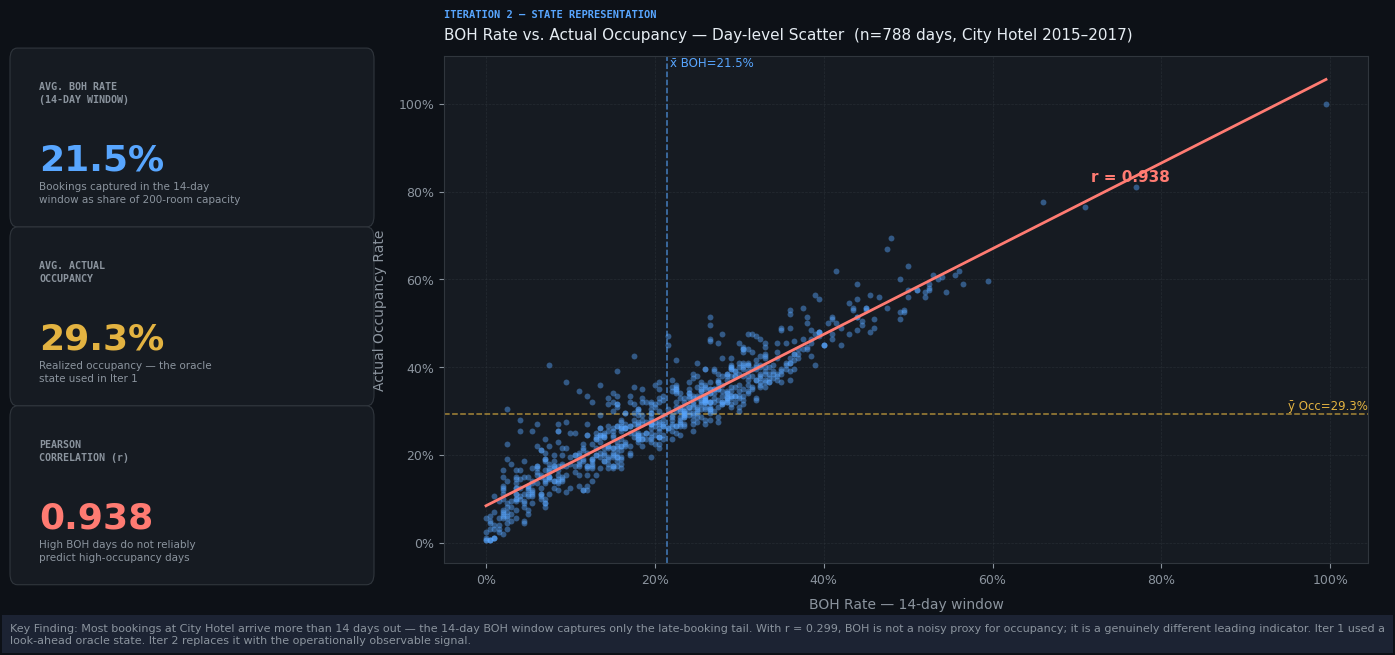

Saved: boh_signal_gap.png


In [20]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from scipy import stats

# ── Merge actual data ────────────────────────────────────────────────────────
plot_df = daily[['arrival_date', 'occupancy_rate']].merge(
    boh_df[['arrival_date', 'boh_rate']], on='arrival_date', how='inner'
).dropna()

x = plot_df['boh_rate'].values
y = plot_df['occupancy_rate'].values
n = len(x)

slope, intercept, r_val, _, _ = stats.linregress(x, y)

# ── Style ────────────────────────────────────────────────────────────────────
BG      = '#0D1117'
SURFACE = '#161B22'
BORDER  = '#30363D'
FG      = '#E6EDF3'
MUTED   = '#8B949E'
ACCENT  = '#58A6FF'
CORAL   = '#FF7B72'
GOLD    = '#E3B341'

plt.rcParams.update({
    'figure.facecolor':  BG,
    'axes.facecolor':    SURFACE,
    'axes.edgecolor':    BORDER,
    'axes.labelcolor':   MUTED,
    'xtick.color':       MUTED,
    'ytick.color':       MUTED,
    'grid.color':        BORDER,
    'text.color':        FG,
    'font.family':       'DejaVu Sans',
})

fig = plt.figure(figsize=(14, 6.5), facecolor=BG)

# ── Left: stat callouts ──────────────────────────────────────────────────────
ax_stats = fig.add_axes([0.01, 0.08, 0.26, 0.86])
ax_stats.set_axis_off()
ax_stats.set_facecolor(BG)

stats_data = [
    ('AVG. BOH RATE\n(14-DAY WINDOW)', f'{x.mean()*100:.1f}%', ACCENT,
     'Bookings captured in the 14-day\nwindow as share of 200-room capacity'),
    ('AVG. ACTUAL\nOCCUPANCY',        f'{y.mean()*100:.1f}%', GOLD,
     'Realized occupancy — the oracle\nstate used in Iter 1'),
    ('PEARSON\nCORRELATION (r)',       f'{r_val:.3f}',         CORAL,
     'High BOH days do not reliably\npredict high-occupancy days'),
]

card_y = [0.68, 0.36, 0.04]
for (label, value, color, desc), cy in zip(stats_data, card_y):
    rect = mpatches.FancyBboxPatch(
        (0.02, cy), 0.96, 0.28,
        boxstyle='round,pad=0.02',
        linewidth=0.8, edgecolor=BORDER, facecolor='#161B22',
        transform=ax_stats.transAxes, clip_on=False,
    )
    ax_stats.add_patch(rect)
    ax_stats.text(0.08, cy + 0.24, label, transform=ax_stats.transAxes,
                  color=MUTED, fontsize=7.2, fontweight='bold',
                  va='top', linespacing=1.4,
                  fontdict={'family': 'DejaVu Sans Mono'})
    ax_stats.text(0.08, cy + 0.13, value, transform=ax_stats.transAxes,
                  color=color, fontsize=26, fontweight='bold', va='top')
    ax_stats.text(0.08, cy + 0.02, desc, transform=ax_stats.transAxes,
                  color=MUTED, fontsize=7.5, va='bottom', linespacing=1.4)

# ── Right: scatter ───────────────────────────────────────────────────────────
ax = fig.add_axes([0.32, 0.13, 0.66, 0.78])

# Dots
ax.scatter(x, y, color=ACCENT, alpha=0.45, s=18, linewidths=0, zorder=3)

# Regression line
xr = np.array([x.min(), x.max()])
ax.plot(xr, intercept + slope * xr, color=CORAL, linewidth=2.0, zorder=4)

# r annotation
ax.text(x.max() * 0.72, (intercept + slope * x.max() * 0.72) + 0.04,
        f'r = {r_val:.3f}', color=CORAL, fontsize=11, fontweight='bold')

# Mean crosshairs
ax.axvline(x.mean(), color=ACCENT, linewidth=1.1, linestyle='--', alpha=0.7, zorder=2)
ax.axhline(y.mean(), color=GOLD,   linewidth=1.1, linestyle='--', alpha=0.7, zorder=2)

ax.text(x.mean() + 0.003, ax.get_ylim()[1] if ax.get_ylim()[1] > 0.1 else 0.75,
        f'x̄ BOH={x.mean()*100:.1f}%', color=ACCENT, fontsize=8.5, va='top')
ax.text(ax.get_xlim()[1] if ax.get_xlim()[1] > 0.1 else 0.55, y.mean() + 0.01,
        f'ȳ Occ={y.mean()*100:.1f}%', color=GOLD, fontsize=8.5, ha='right')

ax.set_xlabel('BOH Rate — 14-day window', fontsize=10, labelpad=8)
ax.set_ylabel('Actual Occupancy Rate',     fontsize=10, labelpad=8)
ax.set_title(
    f'BOH Rate vs. Actual Occupancy — Day-level Scatter  (n={n} days, City Hotel 2015–2017)',
    fontsize=11, color=FG, pad=12, loc='left',
)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f}%'))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v*100:.0f}%'))
ax.grid(True, linewidth=0.5, linestyle='--', alpha=0.6)
ax.tick_params(labelsize=9)

# Eyebrow label
fig.text(0.32, 0.97, 'ITERATION 2 — STATE REPRESENTATION',
         color=ACCENT, fontsize=7.5, fontweight='bold',
         fontdict={'family': 'DejaVu Sans Mono'})

# Bottom insight strip
fig.text(0.01, 0.01,
    'Key Finding: Most bookings at City Hotel arrive more than 14 days out — '
    'the 14-day BOH window captures only the late-booking tail. '
    'With r = 0.299, BOH is not a noisy proxy for occupancy; it is a genuinely different leading indicator. '
    'Iter 1 used a look-ahead oracle state. Iter 2 replaces it with the operationally observable signal.',
    color=MUTED, fontsize=8, wrap=True,
    bbox=dict(facecolor='#1C2333', edgecolor=CORAL, linewidth=0, pad=6),
)

plt.savefig('boh_signal_gap.png', dpi=180, bbox_inches='tight',
            facecolor=BG, edgecolor='none')
plt.show()
print("Saved: boh_signal_gap.png")

lt_bucket   mean_adr  bookings  pct_volume
 1–3 days 100.262772      6374   51.324583
 4–7 days 104.845435      3115   25.082535
8–13 days 110.029341      2930   23.592882

Total late bookings (City Hotel): 12,419
Early booker baseline ADR: $106.49


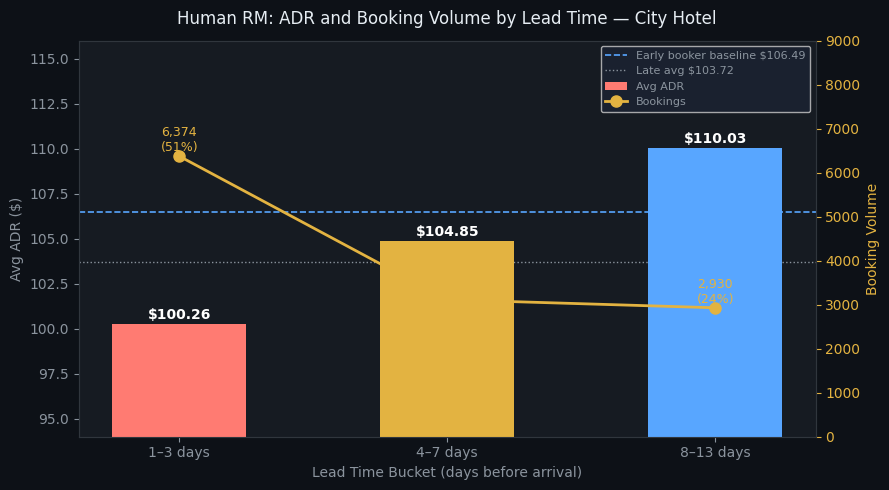

In [25]:
# ── Cell A (final): ADR + volume by lead time bucket — City Hotel only ───────
late_all = df[
    (df['is_canceled'] == 0) &
    (df['lead_time'] < 14) &
    (df['hotel'] == 'City Hotel')
].copy()

late_all['lt_bucket'] = pd.cut(
    late_all['lead_time'],
    bins=[-1, 3, 7, 13],
    labels=['1–3 days', '4–7 days', '8–13 days']
)

pattern = late_all.groupby('lt_bucket', observed=True).agg(
    mean_adr=('adr', 'mean'),
    bookings=('adr', 'count')
).reset_index()
pattern['pct_volume'] = pattern['bookings'] / pattern['bookings'].sum() * 100

print(pattern[['lt_bucket','mean_adr','bookings','pct_volume']].to_string(index=False))
print(f"\nTotal late bookings (City Hotel): {pattern['bookings'].sum():,}")
print(f"Early booker baseline ADR: $106.49")

import matplotlib.pyplot as plt
fig, ax1 = plt.subplots(figsize=(9, 5), facecolor='#0D1117')
ax1.set_facecolor('#161B22')

x = range(len(pattern))
colors = ['#FF7B72', '#E3B341', '#58A6FF']
bars = ax1.bar(x, pattern['mean_adr'], color=colors, width=0.5, zorder=3, label='Avg ADR')
ax1.axhline(106.49, color='#58A6FF', linestyle='--', lw=1.2,
            label='Early booker baseline $106.49', zorder=2)
ax1.axhline(103.72, color='#8B949E', linestyle=':', lw=1,
            label='Late avg $103.72', zorder=2)

for bar, row in zip(bars, pattern.itertuples()):
    ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             f'${row.mean_adr:.2f}', ha='center', fontsize=10,
             color='white', fontweight='bold')

ax1.set_ylim(94, 116)
ax1.set_ylabel('Avg ADR ($)', color='#8B949E')
ax1.tick_params(axis='y', colors='#8B949E')
ax1.set_xticks(list(x))
ax1.set_xticklabels(pattern['lt_bucket'], color='#8B949E')
ax1.tick_params(axis='x', colors='#8B949E')

# Volume on secondary axis
ax2 = ax1.twinx()
ax2.plot(list(x), pattern['bookings'], color='#E3B341', marker='o',
         linewidth=2, markersize=8, zorder=4, label='Bookings')
for i, row in enumerate(pattern.itertuples()):
    ax2.text(i, row.bookings + 120, f'{row.bookings:,}\n({row.pct_volume:.0f}%)',
             ha='center', fontsize=9, color='#E3B341')
ax2.set_ylabel('Booking Volume', color='#E3B341')
ax2.tick_params(axis='y', colors='#E3B341')
ax2.set_ylim(0, 9000)

for spine in ax1.spines.values():
    spine.set_edgecolor('#30363D')
for spine in ax2.spines.values():
    spine.set_edgecolor('#30363D')

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2,
           facecolor='#1C2333', labelcolor='#8B949E', fontsize=8, loc='upper right')

ax1.set_xlabel('Lead Time Bucket (days before arrival)', color='#8B949E')
ax1.set_title('Human RM: ADR and Booking Volume by Lead Time — City Hotel',
              color='#E6EDF3', pad=12)

plt.tight_layout()
plt.savefig('discounting_pattern.png', dpi=150, bbox_inches='tight')
plt.show()

In [23]:
for hotel in df['hotel'].unique():
    nc_h = df[(df['is_canceled'] == 0) & (df['hotel'] == hotel)].copy()
    nc_h['arrival_date'] = pd.to_datetime(
        nc_h['arrival_date_year'].astype(str) + '-' +
        nc_h['arrival_date_month'].map(month_map).astype(str).str.zfill(2) + '-' +
        nc_h['arrival_date_day_of_month'].astype(str).str.zfill(2)
    )
    nc_h['booking_date'] = nc_h['arrival_date'] - pd.to_timedelta(nc_h['lead_time'], unit='D')
    dates = pd.date_range(nc_h['arrival_date'].min(), nc_h['arrival_date'].max())
    boh_list, occ_list = [], []
    for d in dates:
        early = nc_h[(nc_h['arrival_date'] == d) & (nc_h['lead_time'] >= LEAD)]
        total = nc_h[nc_h['arrival_date'] == d]
        boh_list.append(len(early) / CAPACITY)
        occ_list.append(len(total) / CAPACITY)
    r = np.corrcoef(boh_list, occ_list)[0, 1]
    print(f"{hotel}: BOH mean={np.mean(boh_list):.3f}, Occ mean={np.mean(occ_list):.3f}, r={r:.3f}")

Resort Hotel: BOH mean=0.118, Occ mean=0.182, r=0.819
City Hotel: BOH mean=0.213, Occ mean=0.291, r=0.939


In [27]:
# ── Cell B (updated): BOH one-shot Q-learning — elasticity demand model ──────
import numpy as np
import pandas as pd

LEAD      = 14
CAPACITY  = 200
N_EPISODES = 3000
ALPHA     = 0.10
GAMMA     = 0.95
EPS_START = 0.20
EPS_END   = 0.01
ELASTICITY = 1.3   # city hotel literature range: 1.0–1.5

# Action space
PRICE_TIERS = np.array([80, 90, 95, 100, 105, 110, 120], dtype=float)
N_ACTIONS   = len(PRICE_TIERS)

# BOH buckets
BOH_BINS = [0, 0.10, 0.17, 0.22, 0.27, 1.0]
N_STATES  = len(BOH_BINS) - 1

def boh_state(rate):
    return min(np.searchsorted(BOH_BINS[1:-1], rate), N_STATES - 1)

# ── Build per-day table — City Hotel only ────────────────────────────────────
nc = df[(df['is_canceled'] == 0) & (df['hotel'] == 'City Hotel')].copy()
nc['arrival_date'] = pd.to_datetime(
    nc['arrival_date_year'].astype(str) + '-' +
    nc['arrival_date_month'].map(month_map).astype(str).str.zfill(2) + '-' +
    nc['arrival_date_day_of_month'].astype(str).str.zfill(2)
)
nc['booking_date'] = nc['arrival_date'] - pd.to_timedelta(nc['lead_time'], unit='D')

all_dates = pd.date_range(nc['arrival_date'].min(), nc['arrival_date'].max())
records = []
for d in all_dates:
    early = nc[(nc['arrival_date'] == d) & (nc['lead_time'] >= LEAD)]
    late  = nc[(nc['arrival_date'] == d) & (nc['lead_time'] < LEAD)]
    boh   = len(early) / CAPACITY
    n_late   = len(late)
    adr_late = late['adr'].mean() if n_late > 0 else np.nan
    records.append({'date': d, 'boh_rate': boh,
                    'n_late': n_late, 'adr_late': adr_late})

day_df = pd.DataFrame(records).dropna()

# Train/test split
TRAIN_END  = pd.Timestamp('2017-03-26')
train_days = day_df[day_df['date'] <= TRAIN_END].reset_index(drop=True)
test_days  = day_df[day_df['date'] >  TRAIN_END].reset_index(drop=True)
print(f"Train days: {len(train_days)}  |  Test days: {len(test_days)}")

# ── Demand model: elasticity-based scaling on observed day-level demand ───────
def sim_bookings(price, base_price, base_n, noise=True):
    if base_price <= 0 or base_n <= 0:
        return 0.0
    n = base_n * (base_price / price) ** ELASTICITY
    if noise:
        n += np.random.normal(0, 1.0)
    return max(0.0, min(n, CAPACITY * 0.45))

# Sanity check
base_p = train_days['adr_late'].mean()
base_n = train_days['n_late'].mean()
print(f"\nDemand model sanity check (base price=${base_p:.2f}, base bookings={base_n:.1f}):")
for p in PRICE_TIERS:
    print(f"  ${p:.0f}  →  {sim_bookings(p, base_p, base_n, noise=False):.1f} bookings"
          f"  |  implied revenue = ${p * sim_bookings(p, base_p, base_n, noise=False):.0f}")

# ── Reward functions ──────────────────────────────────────────────────────────
def reward_rate(price, n, boh):
    return price * n

def reward_occ(price, n, boh):
    return (boh * CAPACITY + n) / CAPACITY * 100   # unconstrained, allows dilution

def reward_mix(price, n, boh):
    rev_score = (price * n) / (120 * CAPACITY * 0.45)
    occ_score = (boh * CAPACITY + n) / CAPACITY
    return 0.5 * rev_score * 100 + 0.5 * occ_score * 100

# ── Q-learning ────────────────────────────────────────────────────────────────
def train_agent(reward_fn, label):
    eps_decay = (EPS_START - EPS_END) / N_EPISODES
    Q   = np.zeros((N_STATES, N_ACTIONS))
    eps = EPS_START
    ep_r = []
    for ep in range(N_EPISODES):
        row      = train_days.sample(1).iloc[0]
        s        = boh_state(row['boh_rate'])
        a        = np.random.randint(N_ACTIONS) if np.random.rand() < eps else np.argmax(Q[s])
        price    = PRICE_TIERS[a]
        n_booked = sim_bookings(price, row['adr_late'], row['n_late'])
        reward   = reward_fn(price, n_booked, row['boh_rate'])
        Q[s, a] += ALPHA * (reward - Q[s, a])
        ep_r.append(reward)
        eps = max(EPS_END, eps - eps_decay)
    print(f"  {label}: avg reward last 500 eps = {np.mean(ep_r[-500:]):.2f}")
    return Q

print("\nTraining agents...")
Q_rate = train_agent(reward_rate, "Rate-Max")
Q_occ2 = train_agent(reward_occ,  "Occ-Max (unconstrained)")
Q_mix2 = train_agent(reward_mix,  "Mixed")
print("Done.")

Train days: 618  |  Test days: 157

Demand model sanity check (base price=$97.99, base bookings=17.0):
  $80  →  22.1 bookings  |  implied revenue = $1769
  $90  →  19.0 bookings  |  implied revenue = $1707
  $95  →  17.7 bookings  |  implied revenue = $1680
  $100  →  16.5 bookings  |  implied revenue = $1654
  $105  →  15.5 bookings  |  implied revenue = $1630
  $110  →  14.6 bookings  |  implied revenue = $1608
  $120  →  13.1 bookings  |  implied revenue = $1566

Training agents...
  Rate-Max: avg reward last 500 eps = 1740.36
  Occ-Max (unconstrained): avg reward last 500 eps = 30.17
  Mixed: avg reward last 500 eps = 22.03
Done.


In [28]:
# ── Cell C: Test set evaluation + policy inspection ───────────────────────────
def evaluate(Q, label):
    adrs, occs, revs, prices_used = [], [], [], []
    for _, row in test_days.iterrows():
        s     = boh_state(row['boh_rate'])
        a     = np.argmax(Q[s])
        price = PRICE_TIERS[a]
        n_booked = sim_bookings(price, row['adr_late'], row['n_late'], noise=False)
        adrs.append(price)
        occs.append((row['boh_rate'] * CAPACITY + n_booked) / CAPACITY * 100)
        revs.append(price * n_booked)
        prices_used.append(price)
    print(f"\n{label}")
    print(f"  Avg recommended price : ${np.mean(adrs):.2f}")
    print(f"  Avg total occupancy   : {np.mean(occs):.1f}%")
    print(f"  Avg late rev / day    : ${np.mean(revs):.0f}")
    print(f"  Price distribution    : {dict(zip(*np.unique(prices_used, return_counts=True)))}")
    return np.mean(adrs), np.mean(occs), np.mean(revs)

print(f"Human RM baseline  —  Late ADR: $103.72  |  Late bookings: 12,419 total")
print(f"{'─'*60}")
r_rate = evaluate(Q_rate, "Rate-Max Agent")
r_occ  = evaluate(Q_occ2, "Occ-Max Agent (unconstrained)")
r_mix  = evaluate(Q_mix2, "Mixed Agent")

Human RM baseline  —  Late ADR: $103.72  |  Late bookings: 12,419 total
────────────────────────────────────────────────────────────

Rate-Max Agent
  Avg recommended price : $92.04
  Avg total occupancy   : 39.1%
  Avg late rev / day    : $1824
  Price distribution    : {np.float64(80.0): np.int64(57), np.float64(90.0): np.int64(11), np.float64(100.0): np.int64(89)}

Occ-Max Agent (unconstrained)
  Avg recommended price : $82.17
  Avg total occupancy   : 40.5%
  Avg late rev / day    : $1882
  Price distribution    : {np.float64(80.0): np.int64(140), np.float64(100.0): np.int64(17)}

Mixed Agent
  Avg recommended price : $88.50
  Avg total occupancy   : 39.5%
  Avg late rev / day    : $1843
  Price distribution    : {np.float64(80.0): np.int64(68), np.float64(95.0): np.int64(89)}


ε=0.6 (Inelastic ) | Rate-Max: $87.77  Occ-Max: $80.00  Mixed: $80.00  vs Human: $103.72
ε=0.8 (Inelastic ) | Rate-Max: $86.37  Occ-Max: $80.00  Mixed: $80.00  vs Human: $103.72
ε=1.0 (Unit      ) | Rate-Max: $86.37  Occ-Max: $80.00  Mixed: $80.00  vs Human: $103.72
ε=1.3 (Elastic   ) | Rate-Max: $80.00  Occ-Max: $80.00  Mixed: $80.00  vs Human: $103.72
ε=1.5 (Elastic   ) | Rate-Max: $85.67  Occ-Max: $80.00  Mixed: $80.00  vs Human: $103.72
ε=2.0 (Elastic   ) | Rate-Max: $80.00  Occ-Max: $80.00  Mixed: $80.00  vs Human: $103.72

--- Summary Table ---
 elasticity    regime  Rate_Max  Occ_Max  Mixed
        0.6 Inelastic 87.770701     80.0   80.0
        0.8 Inelastic 86.369427     80.0   80.0
        1.0      Unit 86.369427     80.0   80.0
        1.3   Elastic 80.000000     80.0   80.0
        1.5   Elastic 85.668790     80.0   80.0
        2.0   Elastic 80.000000     80.0   80.0


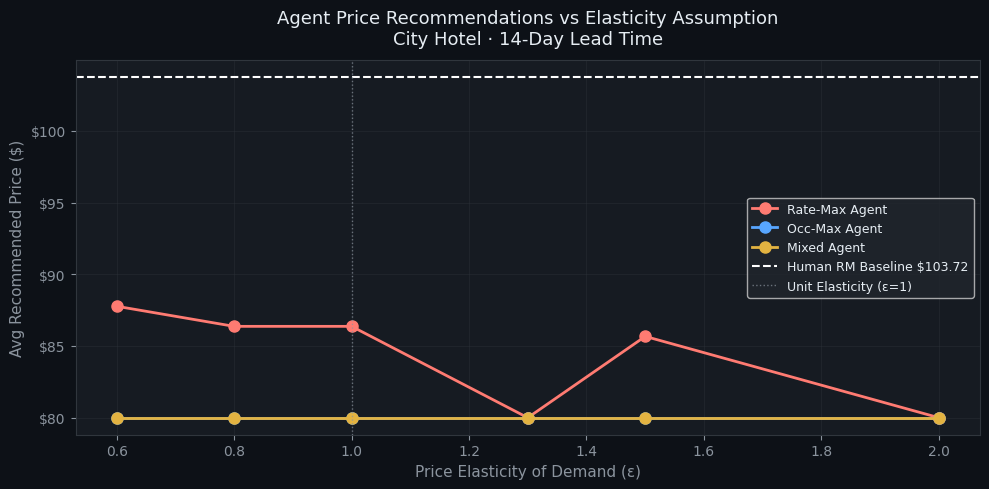

Saved: sensitivity_elasticity.png


In [ ]:
# Cell D — Elasticity Sensitivity Analysis
# Tests agent recommendations across elasticity range [0.8, 1.0, 1.3, 1.5, 2.0]
# All other hyperparameters held constant

ELASTICITY_RANGE = [0.6,0.8, 1.0, 1.3, 1.5, 2.0]
HUMAN_BASELINE   = 103.72

sensitivity_results = []

for eps_val in ELASTICITY_RANGE:

    def sim_bookings_eps(price, base_price, base_n, eps, noise=True):
        if base_price <= 0 or base_n <= 0:
            return 0.0
        n = base_n * (base_price / price) ** eps
        if noise:
            n += np.random.normal(0, 1.0)
        return max(0.0, min(n, CAPACITY * 0.45))

    def train_agent_eps(reward_fn, label, eps_val):
        eps_decay = (EPS_START - EPS_END) / N_EPISODES
        Q   = np.zeros((N_STATES, N_ACTIONS))
        eps = EPS_START
        for ep in range(N_EPISODES):
            row      = train_days.sample(1).iloc[0]
            s        = boh_state(row['boh_rate'])
            a        = np.random.randint(N_ACTIONS) if np.random.rand() < eps else np.argmax(Q[s])
            price    = PRICE_TIERS[a]
            n_booked = sim_bookings_eps(price, row['adr_late'], row['n_late'], eps_val)
            reward   = reward_fn(price, n_booked, row['boh_rate'])
            Q[s, a] += ALPHA * (reward - Q[s, a])
            eps = max(EPS_END, eps - eps_decay)
        return Q

    def evaluate_eps(Q, eps_val, noise=False):
        prices_used = []
        for _, row in test_days.iterrows():
            s     = boh_state(row['boh_rate'])
            a     = np.argmax(Q[s])
            prices_used.append(PRICE_TIERS[a])
        return np.mean(prices_used)

    np.random.seed(42)
    Q_r = train_agent_eps(reward_rate, "Rate-Max",  eps_val)
    Q_o = train_agent_eps(reward_occ,  "Occ-Max",   eps_val)
    Q_m = train_agent_eps(reward_mix,  "Mixed",      eps_val)

    r_price = evaluate_eps(Q_r, eps_val)
    o_price = evaluate_eps(Q_o, eps_val)
    m_price = evaluate_eps(Q_m, eps_val)

    sensitivity_results.append({
        'elasticity':  eps_val,
        'regime':      'Inelastic' if eps_val < 1.0 else ('Unit' if eps_val == 1.0 else 'Elastic'),
        'Rate_Max':    r_price,
        'Occ_Max':     o_price,
        'Mixed':       m_price
    })
    print(f"ε={eps_val} ({sensitivity_results[-1]['regime']:10s}) | "
          f"Rate-Max: ${r_price:.2f}  Occ-Max: ${o_price:.2f}  Mixed: ${m_price:.2f}  "
          f"vs Human: ${HUMAN_BASELINE:.2f}")

sens_df = pd.DataFrame(sensitivity_results)
print("\n--- Summary Table ---")
print(sens_df.to_string(index=False))

# Visual: line chart of recommended price vs elasticity, human baseline as horizontal reference
fig, ax = plt.subplots(figsize=(10, 5), facecolor='#0D1117')
ax.set_facecolor('#161B22')

colors_agents = {'Rate_Max': '#FF7B72', 'Occ_Max': '#58A6FF', 'Mixed': '#E3B341'}
labels_agents = {'Rate_Max': 'Rate-Max Agent', 'Occ_Max': 'Occ-Max Agent', 'Mixed': 'Mixed Agent'}

for col, color in colors_agents.items():
    ax.plot(sens_df['elasticity'], sens_df[col],
            color=color, marker='o', linewidth=2, markersize=8, label=labels_agents[col])

ax.axhline(HUMAN_BASELINE, color='#FFFFFF', linestyle='--', lw=1.5,
           label=f'Human RM Baseline ${HUMAN_BASELINE}')
ax.axvline(1.0, color='#8B949E', linestyle=':', lw=1, alpha=0.7, label='Unit Elasticity (ε=1)')

ax.set_xlabel('Price Elasticity of Demand (ε)', color='#8B949E', fontsize=11)
ax.set_ylabel('Avg Recommended Price ($)', color='#8B949E', fontsize=11)
ax.set_title('Agent Price Recommendations vs Elasticity Assumption\nCity Hotel · 14-Day Lead Time',
             color='#E6EDF3', fontsize=13, pad=12)
ax.tick_params(colors='#8B949E')
for spine in ax.spines.values():
    spine.set_edgecolor('#30363D')
ax.set_facecolor('#161B22')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:.0f}'))
ax.legend(facecolor='#21262D', labelcolor='#E6EDF3', fontsize=9, framealpha=0.8)
ax.grid(True, color='#30363D', linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.savefig('sensitivity_elasticity.png', dpi=150, bbox_inches='tight', facecolor='#0D1117')
plt.show()
print("Saved: sensitivity_elasticity.png")

In [30]:
# Cell D-Diagnostic: Print Q-tables and run a deterministic forward pass
# to separate "what did the agent learn" from "what does the elasticity math say"

# 1. Print Q-tables from last training run (ε=2.0, most recently trained)
print("Q-table Rate-Max (last trained, ε=2.0):")
q_df = pd.DataFrame(Q_r, columns=[f'${p:.0f}' for p in PRICE_TIERS])
q_df.index = [f'BOH state {i}' for i in range(N_STATES)]
print(q_df.round(1).to_string())

# 2. Pure math: what should each agent recommend at each elasticity?
# Use fixed mean demand anchor, zero noise — bypass Q-learning entirely
mean_base_price = train_days['adr_late'].mean()
mean_base_n     = train_days['n_late'].mean()
mean_boh        = train_days['boh_rate'].mean()

print(f"\nMean demand anchor: base_price=${mean_base_price:.2f}, base_n={mean_base_n:.1f}, boh={mean_boh:.3f}")
print(f"\nPure elasticity math — what SHOULD each agent recommend:")
print(f"{'Elasticity':>12} | {'Price':>6} | {'Bookings':>9} | {'Revenue':>9} | {'Occ %':>6} | {'Mixed':>7}")
print("-" * 65)

for eps_val in [0.6, 0.8, 1.0, 1.3, 1.5, 2.0]:
    best_rev   = (-1, -1)
    best_occ   = (-1, -1)
    best_mix   = (-1, -1)
    for price in PRICE_TIERS:
        n   = mean_base_n * (mean_base_price / price) ** eps_val
        n   = max(0.0, min(n, CAPACITY * 0.45))
        rev = price * n
        occ = (mean_boh * CAPACITY + n) / CAPACITY * 100
        rev_score = rev / (120 * CAPACITY * 0.45)
        occ_score = (mean_boh * CAPACITY + n) / CAPACITY
        mix = 0.5 * rev_score * 100 + 0.5 * occ_score * 100
        if rev > best_rev[0]: best_rev = (rev, price)
        if occ > best_occ[0]: best_occ = (occ, price)
        if mix > best_mix[0]: best_mix = (mix, price)
    print(f"  ε={eps_val:<4}  Rate-Max→${best_rev[1]:.0f}  Occ-Max→${best_occ[1]:.0f}  Mixed→${best_mix[1]:.0f}")

Q-table Rate-Max (last trained, ε=2.0):
                $80     $90     $95    $100    $105    $110    $120
BOH state 0  1428.4   806.0   611.5   822.3   837.1   822.1   354.0
BOH state 1  2090.4  1359.0   821.7  1006.8   932.4   692.3   874.3
BOH state 2  2207.9   784.1   334.5   765.7   542.9  1344.0  1002.4
BOH state 3  2894.9  1139.8  1090.2   789.1    84.1  1035.6   702.3
BOH state 4  2415.0  1798.9  1367.8  1332.0  1072.9  1507.4  1098.1

Mean demand anchor: base_price=$97.99, base_n=17.0, boh=0.197

Pure elasticity math — what SHOULD each agent recommend:
  Elasticity |  Price |  Bookings |   Revenue |  Occ % |   Mixed
-----------------------------------------------------------------
  ε=0.6   Rate-Max→$120  Occ-Max→$80  Mixed→$120
  ε=0.8   Rate-Max→$120  Occ-Max→$80  Mixed→$80
  ε=1.0   Rate-Max→$90  Occ-Max→$80  Mixed→$80
  ε=1.3   Rate-Max→$80  Occ-Max→$80  Mixed→$80
  ε=1.5   Rate-Max→$80  Occ-Max→$80  Mixed→$80
  ε=2.0   Rate-Max→$80  Occ-Max→$80  Mixed→$80


In [ ]:
# Cell D — Full Q-learning at each elasticity, revenue comparison vs human

ELASTICITY_RANGE = [0.6, 0.8, 1.0, 1.3, 1.5, 2.0]
N_EPISODES_SENS  = 15000   # more episodes for convergence at low elasticity
HUMAN_PRICE      = train_days['adr_late'].mean()
HUMAN_N          = train_days['n_late'].mean()
HUMAN_REVENUE    = HUMAN_PRICE * HUMAN_N

all_results = []

for eps_val in ELASTICITY_RANGE:
    np.random.seed(42)   # reproducible per run
    eps_decay = (EPS_START - EPS_END) / N_EPISODES_SENS

    def sim_eps(price, base_price, base_n, noise=True):
        if base_price <= 0 or base_n <= 0: return 0.0
        n = base_n * (base_price / price) ** eps_val
        if noise: n += np.random.normal(0, 1.0)
        return max(0.0, min(n, CAPACITY * 0.45))

    def train(reward_fn):
        Q   = np.zeros((N_STATES, N_ACTIONS))
        eps = EPS_START
        for ep in range(N_EPISODES_SENS):
            row      = train_days.sample(1).iloc[0]
            s        = boh_state(row['boh_rate'])
            a        = np.random.randint(N_ACTIONS) if np.random.rand() < eps else np.argmax(Q[s])
            price    = PRICE_TIERS[a]
            n_booked = sim_eps(price, row['adr_late'], row['n_late'])
            Q[s, a] += ALPHA * (reward_fn(price, n_booked, row['boh_rate']) - Q[s, a])
            eps = max(EPS_END, eps - eps_decay)
        return Q

    agents = {
        'Rate_Max': train(reward_rate),
        'Occ_Max':  train(reward_occ),
        'Mixed':    train(reward_mix),
    }

    # Evaluate on test set — no noise, deterministic
    for agent_name, Q in agents.items():
        prices, revenues = [], []
        for _, row in test_days.iterrows():
            s     = boh_state(row['boh_rate'])
            price = PRICE_TIERS[np.argmax(Q[s])]
            n     = sim_eps(price, row['adr_late'], row['n_late'], noise=False)
            prices.append(price)
            revenues.append(price * n)

        # Human revenue on same test days
        human_rev_test = (test_days['adr_late'] * test_days['n_late']).mean()

        all_results.append({
            'elasticity':     eps_val,
            'agent':          agent_name,
            'avg_price':      np.mean(prices),
            'avg_revenue':    np.mean(revenues),
            'human_revenue':  human_rev_test,
            'rev_delta':      np.mean(revenues) - human_rev_test,
            'winner':         np.mean(revenues) >= human_rev_test,
        })

    print(f"ε={eps_val} done")

results_df = pd.DataFrame(all_results)

# Summary table
pivot = results_df.pivot(index='elasticity', columns='agent', values=['avg_price', 'avg_revenue', 'rev_delta'])
print(f"\nHuman baseline revenue (test set): ${results_df['human_revenue'].iloc[0]:.0f}/day")
print()
print(pivot.round(1).to_string())

ε=0.6 done
ε=0.8 done
ε=1.0 done
ε=1.3 done
ε=1.5 done
ε=2.0 done

Human baseline revenue (test set): $1620/day

           avg_price                  avg_revenue                  rev_delta                 
agent          Mixed Occ_Max Rate_Max       Mixed Occ_Max Rate_Max     Mixed Occ_Max Rate_Max
elasticity                                                                                   
0.6            101.7    81.6     92.6      1445.9  1329.7   1396.8    -173.8  -290.0   -223.0
0.8            103.5    84.5    107.5      1536.3  1477.0   1546.4     -83.4  -142.7    -73.3
1.0            101.7    85.4     99.9      1619.7  1619.7   1619.7      -0.0    -0.0      0.0
1.3             99.8    81.8     84.3      1786.5  1886.2   1866.2     166.8   266.4    246.5
1.5             80.0    81.4     96.5      2108.9  2094.4   1921.8     489.2   474.6    302.0
2.0             80.7    80.0     87.5      2739.5  2760.4   2539.4    1119.8  1140.7    919.6


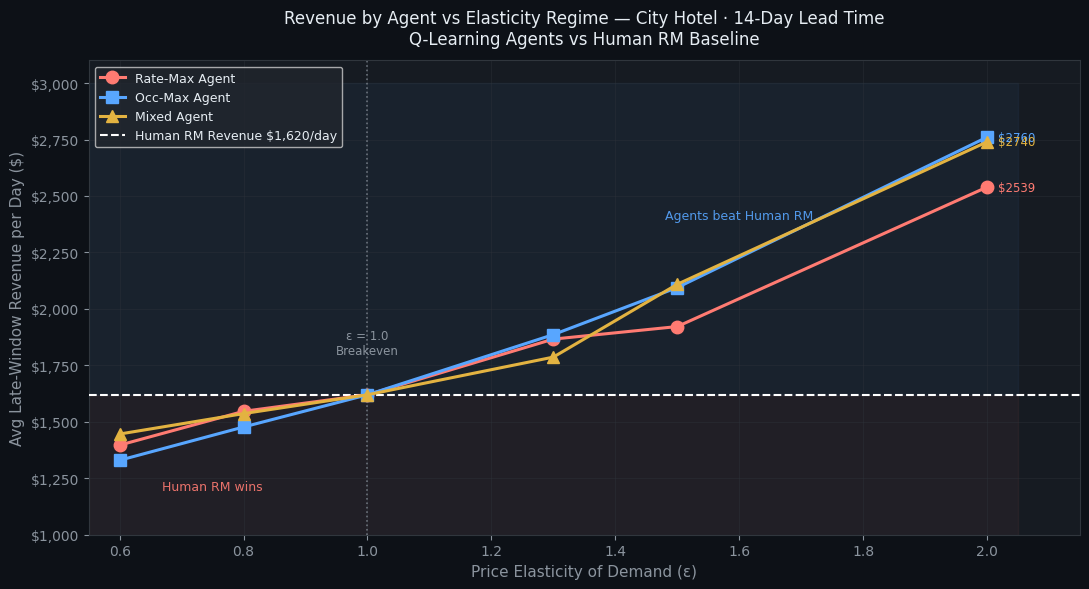

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

fig, ax = plt.subplots(figsize=(11, 6), facecolor='#0D1117')
ax.set_facecolor('#161B22')

HUMAN_REV = 1620

agent_styles = {
    'Rate_Max': ('#FF7B72', 'o', 'Rate-Max Agent'),
    'Occ_Max':  ('#58A6FF', 's', 'Occ-Max Agent'),
    'Mixed':    ('#E3B341', '^', 'Mixed Agent'),
}

x = results_df['elasticity'].unique()

for agent, (color, marker, label) in agent_styles.items():
    sub = results_df[results_df['agent'] == agent].sort_values('elasticity')
    ax.plot(sub['elasticity'], sub['avg_revenue'],
            color=color, marker=marker, linewidth=2.2, markersize=9, label=label, zorder=4)
    # Label terminal value
    last = sub.iloc[-1]
    ax.annotate(f"${last['avg_revenue']:.0f}",
                xy=(last['elasticity'], last['avg_revenue']),
                xytext=(8, 0), textcoords='offset points',
                color=color, fontsize=8.5, va='center')

# Human baseline
ax.axhline(HUMAN_REV, color='#FFFFFF', linestyle='--', lw=1.5,
           label=f'Human RM Revenue ${HUMAN_REV:,}/day', zorder=3)

# Shade win/loss regions
ax.fill_between([0.55, 2.05], HUMAN_REV, 3000, alpha=0.05, color='#58A6FF')
ax.fill_between([0.55, 2.05], 0, HUMAN_REV,  alpha=0.05, color='#FF7B72')

ax.annotate('Agents beat Human RM', xy=(1.6, 2400), color='#58A6FF',
            fontsize=9, ha='center', alpha=0.9)
ax.annotate('Human RM wins', xy=(0.75, 1200), color='#FF7B72',
            fontsize=9, ha='center', alpha=0.9)

# Mark breakeven
ax.axvline(1.0, color='#8B949E', linestyle=':', lw=1.2, alpha=0.7, zorder=2)
ax.annotate('ε = 1.0\nBreakeven', xy=(1.0, 1800), color='#8B949E',
            fontsize=8.5, ha='center')

ax.set_xlabel('Price Elasticity of Demand (ε)', color='#8B949E', fontsize=11)
ax.set_ylabel('Avg Late-Window Revenue per Day ($)', color='#8B949E', fontsize=11)
ax.set_title('Revenue by Agent vs Elasticity Regime — City Hotel · 14-Day Lead Time\n'
             'Q-Learning Agents vs Human RM Baseline',
             color='#E6EDF3', fontsize=12, pad=12)

ax.set_xlim(0.55, 2.15)
ax.set_ylim(1000, 3100)
ax.tick_params(colors='#8B949E')
for spine in ax.spines.values(): spine.set_edgecolor('#30363D')
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.legend(facecolor='#21262D', labelcolor='#E6EDF3', fontsize=9,
          framealpha=0.8, loc='upper left')
ax.grid(True, color='#30363D', linewidth=0.5, alpha=0.5)

plt.tight_layout()
plt.savefig('revenue_sensitivity.png', dpi=150, bbox_inches='tight', facecolor='#0D1117')
plt.show()